<a href="https://colab.research.google.com/github/bosic2/AlgoCom/blob/main/Benchmarking_DynamicDifficulty.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Benchmarking Algorithms: Dynamic Difficulty

**[Problem]:**

Dynamically adjusting difficulty levels based on player performance, checking for the base’s health to dynamically adjust enemy spawns for the next incoming subwave



---




**[Algorithms Used]:**
1. Direct Thresholds (similar to PvZ)
2. PID Controller
3. Fuzzy Logic


---

**[Metrics]:**
1. Speed
2. Scalability
3. Functionality

Running engine prototype benchmarks (50,000 iterations)...


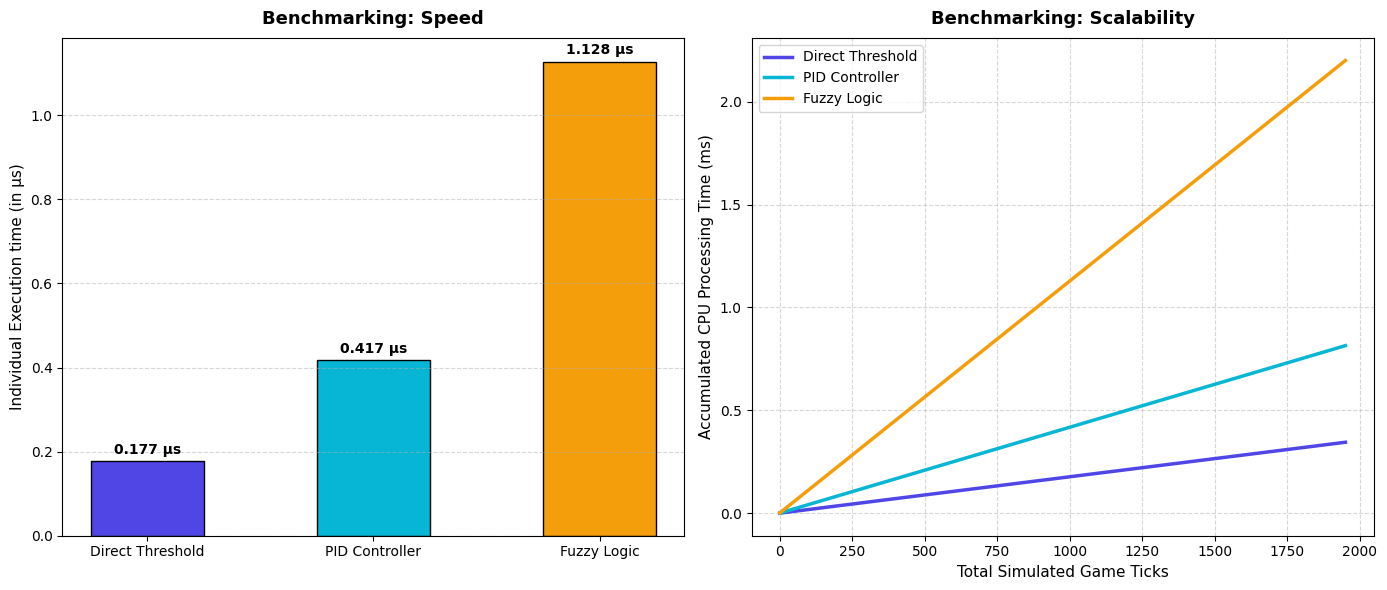

In [ ]:
import time
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Algorithm 1: Direct Threshold
class DirectThreshold:
    def __init__(self, target=15.0):
        self.target = target

    def update(self, current):
        error = current - self.target
        if error > 3.0:
            return 1.5
        elif error < -3.0:
            return 0.5
        return 1.0

# Algorithm 2: PID Controller
class PIDController:
    def __init__(self, target=15.0, kp=0.1, ki=0.01, kd=0.05):
        self.target = target
        self.kp, self.ki, self.kd = kp, ki, kd
        self.integral = 0.0
        self.prev_error = 0.0

    def update(self, current, dt=1.0):
        error = current - self.target
        self.integral += error * dt
        derivative = (error - self.prev_error) / dt
        self.prev_error = error
        return 1.0 + (self.kp * error + self.ki * self.integral + self.kd * derivative)

# Algorithm 3: Fuzzy Logic
class SimpleFuzzyLogic:
    def __init__(self, target=15.0):
        self.target = target

    def _trimf(self, x, a, b, c):
        return max(0.0, min((x - a) / (b - a) if b > a else 1.0, (c - x) / (c - b) if c > b else 1.0))

    def update(self, current):
        error = current - self.target

        low = self._trimf(error, -10.0, -5.0, 0.0)
        ok = self._trimf(error, -3.0, 0.0, 3.0)
        high = self._trimf(error, 0.0, 5.0, 10.0)

        total_weight = low + ok + high
        if total_weight == 0:
            return 1.0

        return (low * 0.5 + ok * 1.0 + high * 1.5) / total_weight

if __name__ == "__main__":
    ITERATIONS = 50000
    print(f"Running engine prototype benchmarks ({ITERATIONS:,} iterations)...")

    dt_dda = DirectThreshold()
    pid_dda = PIDController()
    fuzzy_dda = SimpleFuzzyLogic()

    # Measure Direct Threshold
    t0 = time.perf_counter()
    for _ in range(ITERATIONS):
        dt_dda.update(12.0)
    dt_time = (time.perf_counter() - t0) / ITERATIONS * 1e6

    # Measure PID
    t0 = time.perf_counter()
    for _ in range(ITERATIONS):
        pid_dda.update(12.0)
    pid_time = (time.perf_counter() - t0) / ITERATIONS * 1e6

    # Measure Fuzzy Logic
    t0 = time.perf_counter()
    for _ in range(ITERATIONS):
        fuzzy_dda.update(12.0)
    fuzzy_time = (time.perf_counter() - t0) / ITERATIONS * 1e6

    recorded_frames = np.arange(1, 2001, 50)
    df = pd.DataFrame({
        "Simulated_Frames": recorded_frames,
        "Direct_Threshold_ms": (recorded_frames * dt_time) / 1000,
        "PID_Controller_ms": (recorded_frames * pid_time) / 1000,
        "Fuzzy_Logic_ms": (recorded_frames * fuzzy_time) / 1000
    })

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

    algorithms = ['Direct Threshold', 'PID Controller', 'Fuzzy Logic']
    times = [dt_time, pid_time, fuzzy_time]
    colors = ['#4f46e5', '#06b6d4', '#f59e0b']

    bars = ax1.bar(algorithms, times, color=colors, edgecolor='black', width=0.5)
    ax1.set_ylabel('Individual Execution time (in μs)', fontsize=11)
    ax1.set_title('Benchmarking: Speed', fontsize=13, fontweight='bold', pad=10)
    ax1.grid(axis='y', linestyle='--', alpha=0.5)

    for bar in bars:
        height = bar.get_height()
        ax1.annotate(f'{height:.3f} μs',
                    xy=(bar.get_x() + bar.get_width() / 2, height),
                    xytext=(0, 3),
                    textcoords="offset points",
                    ha='center', va='bottom', fontweight='bold')

    ax2.plot(df['Simulated_Frames'], df['Direct_Threshold_ms'], label='Direct Threshold', color='#4f46e5', linewidth=2.5)
    ax2.plot(df['Simulated_Frames'], df['PID_Controller_ms'], label='PID Controller', color='#06b6d4', linewidth=2.5)
    ax2.plot(df['Simulated_Frames'], df['Fuzzy_Logic_ms'], label='Fuzzy Logic', color='#f59e0b', linewidth=2.5)

    ax2.set_xlabel('Total Simulated Game Ticks', fontsize=11)
    ax2.set_ylabel('Accumulated CPU Processing Time (ms)', fontsize=11)
    ax2.set_title('Benchmarking: Scalability', fontsize=13, fontweight='bold', pad=10)
    ax2.legend(loc='upper left')
    ax2.grid(True, linestyle='--', alpha=0.5)

    plt.tight_layout()
    plt.show()

 ## Results

###1. Speed
 As we can see, the benchmark ing results show that the fastest algorithm is **Direct Threshold** with a 0.18 microsecond per individual call, and scales very nicely from the benchmarking chart. However, **PID Controller** is close with an individual call time of 0.42 microseconds. **Fuzzy Logic** has the highest call time with 1.13 microseconds.

###2. Scalability
Direct Threshold scales very well, still going less than 0.5 milliseconds after 2000 in-game ticks. PID Controller still goes under 1 millisecond after 2000 in-game ticks. Fuzzy Logic goes just above 2 milliseconds after 2000 in-game ticks.

###3. Functionality
Direct Threshold is very simple and fast, but does not smoothly adjust difficulty. Instead, it jumps between states instead of slowly transitioning between them. PID controller excels more in linear and well-defined systems, while Fuzzy Logic is best for complex systems with more unknowns.

##Conclusion
 Ultimately, we have decided to go for the **PID Controller** in the end because it is similar in speed to the fastest algorithm, but is more dynamic and has a more gradual curve compared to Direct Threshold. Fuzzy Logic is also a plausible candidate, but we find that the complexity of the game isn't that high, and PID strikes a nice middle ground between speed and complexity.